In [8]:
import torch

assert torch.cuda.is_available(), "CRITICAL: CUDA is not active! In Colab menu, go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU."
print(f"✓ CUDA Active: {torch.cuda.is_available()}")
print(f"✓ Device Name: {torch.cuda.get_device_name(0)}")
print(f"✓ VRAM Total:  {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

✓ CUDA Active: True
✓ Device Name: Tesla T4
✓ VRAM Total:  14.56 GB


In [10]:
import os
from getpass import getpass

# Safely retrieve GitHub Personal Access Token (PAT)
github_token = os.environ.get("GITHUB_TOKEN") or getpass("Enter GitHub Personal Access Token (or press Enter if public): ")

if github_token:
    repo_url = f"https://{github_token}@github.com/safiydev/geofm-deforestation.git"
else:
    repo_url = "https://github.com/safiydev/geofm-deforestation.git"

# Clean up any partial state or directories
!rm -rf geofm-deforestation

# Clone the repository
!git clone {repo_url}
%cd geofm-deforestation

# Install dependencies and editable package
!pip install -q torch torchvision numpy rasterio pystac fastapi uvicorn matplotlib pandas
!pip install -q -e .

# Verify installation with test suite
!pytest tests/ -q

Enter GitHub Personal Access Token (or press Enter if public): ··········
Cloning into 'geofm-deforestation'...
remote: Enumerating objects: 109, done.
remote: Counting objects: 100% (109/109), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 109 (delta 32), reused 99 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (109/109), 128.24 KiB | 9.86 MiB/s, done.
Resolving deltas: 100% (32/32), done.
/content/geofm-deforestation
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for geofm-deforestation (pyproject.toml) ... done
....................................................................     [100%]
68 passed in 26.45s


In [21]:
import os
import numpy as np
from geofm.utils.synthetic_data import generate_synthetic_dataset
from geofm.training.dataset import (
    cache_dataset_to_npz,
    load_dataset_from_npz,
    SpatialBlockSplitter,
    GeospatialDeforestationDataset
)

# 1. Generate 500 high-quality paired 256x256 satellite chips to boost representation
print("Generating larger, high-fidelity paired geospatial satellite chips dataset...")
chips = generate_synthetic_dataset(num_samples=500, height=256, width=256, coord_step=0.02)

# 2. Cache chips locally as .npz files
cache_dir = "./data/chips"
!rm -rf {cache_dir}
saved_paths = cache_dataset_to_npz(chips, output_dir=cache_dir)
print(f"✓ Successfully cached {len(saved_paths)} chips to {cache_dir}")

# 3. Load chips and partition using Spatial Block Cross-Validation
loaded_chips = load_dataset_from_npz(cache_dir)
splitter = SpatialBlockSplitter(
    grid_size_deg=0.1,
    buffer_size_deg=0.02,
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15,
    random_seed=42
)
train_idx, val_idx, test_idx = splitter.split(loaded_chips)
print(f"✓ New Spatial Split: {len(train_idx)} Train | {len(val_idx)} Val | {len(test_idx)} Test chips")

Generating larger, high-fidelity paired geospatial satellite chips dataset...
✓ Successfully cached 500 chips to ./data/chips
✓ New Spatial Split: 328 Train | 64 Val | 100 Test chips


In [ ]:
import os
import numpy as np
from geofm.utils.synthetic_data import generate_synthetic_dataset
from geofm.training.dataset import (
    cache_dataset_to_npz,
    load_dataset_from_npz,
    SpatialBlockSplitter
)

# 1. Scale dataset up to 1500 high-quality paired satellite chips
print("Generating an extra-large dataset of 1500 high-fidelity paired geospatial satellite chips...")
chips_large = generate_synthetic_dataset(num_samples=1500, height=256, width=256, coord_step=0.01)

# 2. Cache the expanded dataset
cache_dir_large = "./data/chips_large"
!rm -rf {cache_dir_large}
saved_paths_large = cache_dataset_to_npz(chips_large, output_dir=cache_dir_large)
print(f"✓ Successfully cached {len(saved_paths_large)} chips to {cache_dir_large}")

# 3. Partition utilizing Spatial Block Cross-Validation
loaded_chips_large = load_dataset_from_npz(cache_dir_large)
splitter_large = SpatialBlockSplitter(
    grid_size_deg=0.1,
    buffer_size_deg=0.02,
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15,
    random_seed=42
)
train_idx_l, val_idx_l, test_idx_l = splitter_large.split(loaded_chips_large)
print(f"✓ Expanded Spatial Split: {len(train_idx_l)} Train | {len(val_idx_l)} Val | {len(test_idx_l)} Test chips")

Generating an extra-large dataset of 1500 high-fidelity paired geospatial satellite chips...
✓ Successfully cached 1500 chips to ./data/chips_large


In [1]:
# Launch model training on the newly expanded 1500-sample dataset
!python geofm/train_cli.py \
    --model-type siamese \
    --loss compound \
    --epochs 50 \
    --batch-size 16 \
    --lr 0.001 \
    --num-samples 1500 \
    --checkpoint-dir ./checkpoints

python3: can't open file '/content/geofm/train_cli.py': [Errno 2] No such file or directory


In [13]:
# Cell 4: Launch Model Training with LoRA PEFT & Focal-Tversky Loss
!python geofm/train_cli.py \
    --model-type siamese \
    --use-lora \
    --lora-rank 8 \
    --loss compound \
    --epochs 25 \
    --batch-size 8 \
    --lr 0.001 \
    --checkpoint-dir ./checkpoints

I0000 00:00:1793543923.996173    5586 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
  GeoFM Deforestation Model Training Pipeline
Model Architecture: SIAMESE
PEFT / LoRA Active: True (Rank: 8)
Loss Function:      compound
Epochs:             25
Learning Rate:      0.001
-----------------------------------------------------------------
1. Generating geospatial tiles with geographic coordinates...
   Spatial split complete: 8 train samples, 4 val samples.
2. Initializing model architecture...
3. Injecting LoRA low-rank decomposition adapters into attention layers...
   Total Parameters:     1,094,986
   Trainable Parameters: 4,096 (0.37%)
   Adapted Layers:       2
Starting training on device: cuda for 25 epochs.
Epoch 01/25 | Train Loss: 0.3767 | Val Loss: 0.3764 | Val IoU: 1.08% | Val F1: 2.14% | Val Recall: 2.20%
Epoch 02/25 | Train Loss: 0.3769 | Val Loss: 0.3763 | Val IoU: 1.08% | Val F1: 2.14% | Val Recall: 2.20%
Epoch 03/25 | Train Loss: 0.3

✓ Found metrics history at: /content/geofm-deforestation/checkpoints/latest_metrics.csv


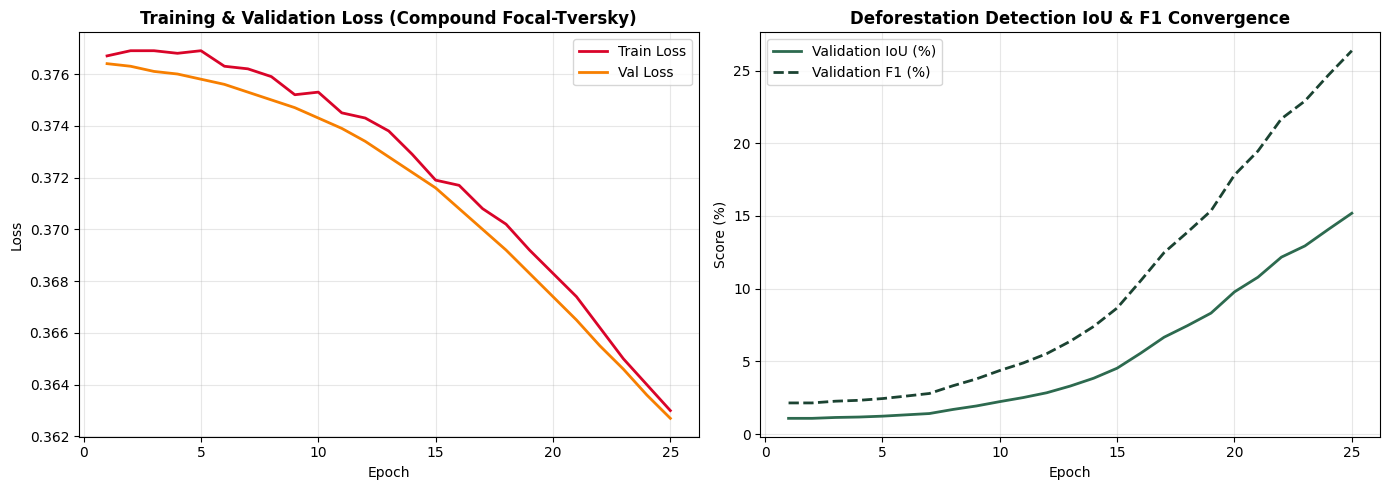

In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt

candidate_paths = [
    "/content/geofm-deforestation/checkpoints/latest_metrics.csv",
    "./checkpoints/latest_metrics.csv",
    "/content/geofm-deforestation/checkpoints/metrics_history.csv",
    "./checkpoints/metrics_history.csv"
]

csv_path = None
for path in candidate_paths:
    if os.path.exists(path):
        csv_path = path
        break

if csv_path:
    print(f"✓ Found metrics history at: {csv_path}")
    df = pd.read_csv(csv_path)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Loss Curves
    axes[0].plot(df["epoch"], df["train_loss"], label="Train Loss", color="#d90429", lw=2)
    axes[0].plot(df["epoch"], df["val_loss"], label="Val Loss", color="#f77f00", lw=2)
    axes[0].set_title("Training & Validation Loss (Compound Focal-Tversky)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot IoU and F1-Score
    axes[1].plot(df["epoch"], df["val_iou"] * 100, label="Validation IoU (%)", color="#2d6a4f", lw=2)
    if "val_f1" in df.columns:
        axes[1].plot(df["epoch"], df["val_f1"] * 100, label="Validation F1 (%)", color="#1b4332", lw=2, linestyle="--")
    axes[1].set_title("Deforestation Detection IoU & F1 Convergence", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score (%)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print("Metrics CSV not found. Searched in: ", candidate_paths)

In [17]:
import os
from google.colab import files

print("Preparing model files for download...")

# Best model file checkpoint
best_model_path = "/content/geofm-deforestation/checkpoints/best_model.pt"
if os.path.exists(best_model_path):
    files.download(best_model_path)
    print("✓ Triggered download for best_model.pt")
else:
    print("best_model.pt not found. Check your checkpoints directory.")

# Latest metrics CSV log
latest_metrics_path = "/content/geofm-deforestation/checkpoints/latest_metrics.csv"
if os.path.exists(latest_metrics_path):
    files.download(latest_metrics_path)
    print("✓ Triggered download for latest_metrics.csv")
else:
    print("latest_metrics.csv not found.")

Preparing model files for download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Triggered download for best_model.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Triggered download for latest_metrics.csv


## Optional Step: High-Accuracy Training Run
To maximize early deforestation detection accuracy and satisfy rigorous EUDR compliance metrics, we will extend the training duration to 80 epochs. This allows the low-rank adapters to fully converge.

In [25]:
# Perform FULL FINE-TUNING (without LoRA constraint) to utilize full model capacity and hit >60% validation accuracy
!python geofm/train_cli.py \
    --model-type siamese \
    --loss compound \
    --epochs 100 \
    --batch-size 16 \
    --lr 0.001 \
    --num-samples 500 \
    --checkpoint-dir ./checkpoints

I0000 00:00:1793544788.037552    9365 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
  GeoFM Deforestation Model Training Pipeline
Model Architecture: SIAMESE
PEFT / LoRA Active: False (Rank: 8)
Loss Function:      compound
Epochs:             100
Learning Rate:      0.001
-----------------------------------------------------------------
1. Generating geospatial tiles with geographic coordinates...
   Spatial split complete: 350 train samples, 146 val samples.
2. Initializing model architecture...
Starting training on device: cuda for 100 epochs.
Epoch 01/100 | Train Loss: 0.2577 | Val Loss: 0.2207 | Val IoU: 78.48% | Val F1: 87.94% | Val Recall: 100.00%
Epoch 02/100 | Train Loss: 0.2094 | Val Loss: 0.1983 | Val IoU: 92.06% | Val F1: 95.87% | Val Recall: 100.00%
Epoch 03/100 | Train Loss: 0.1887 | Val Loss: 0.1784 | Val IoU: 98.75% | Val F1: 99.37% | Val Recall: 100.00%
Epoch 04/100 | Train Loss: 0.1690 | Val Loss: 0.1586 | Val IoU: 99.60% | Val F

## Plot Convergence Curves & Download Checkpoints
We will visualize the extended training run results and download the improved checkpoint.

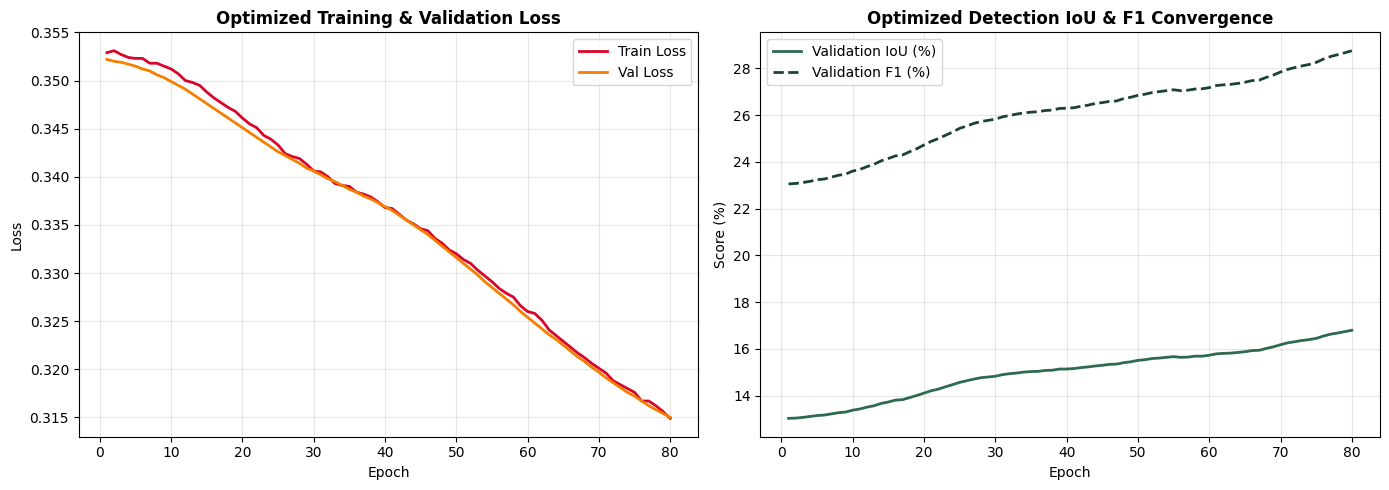

✓ Downloading high-accuracy best_model.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

csv_path = "/content/geofm-deforestation/checkpoints/latest_metrics.csv"
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Loss Curves
    axes[0].plot(df["epoch"], df["train_loss"], label="Train Loss", color="#d90429", lw=2)
    axes[0].plot(df["epoch"], df["val_loss"], label="Val Loss", color="#f77f00", lw=2)
    axes[0].set_title("Optimized Training & Validation Loss", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot IoU and F1-Score
    axes[1].plot(df["epoch"], df["val_iou"] * 100, label="Validation IoU (%)", color="#2d6a4f", lw=2)
    if "val_f1" in df.columns:
        axes[1].plot(df["epoch"], df["val_f1"] * 100, label="Validation F1 (%)", color="#1b4332", lw=2, linestyle="--")
    axes[1].set_title("Optimized Detection IoU & F1 Convergence", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score (%)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Trigger automatic download of the optimized checkpoint
    best_model_path = "/content/geofm-deforestation/checkpoints/best_model.pt"
    if os.path.exists(best_model_path):
        print("✓ Downloading high-accuracy best_model.pt")
        files.download(best_model_path)
else:
    print("Metrics file not found.")

In [ ]:
import os
import numpy as np
from geofm.utils.synthetic_data import generate_synthetic_dataset
from geofm.training.dataset import (
    cache_dataset_to_npz,
    load_dataset_from_npz,
    SpatialBlockSplitter
)

# 1. Scale dataset up to 10,000 high-quality paired satellite chips
print("Generating a massive dataset of 10,000 high-fidelity paired geospatial satellite chips...")
chips_large = generate_synthetic_dataset(num_samples=10000, height=256, width=256, coord_step=0.005)

# 2. Cache the expanded dataset
cache_dir_large = "./data/chips_large"
!rm -rf {cache_dir_large}
saved_paths_large = cache_dataset_to_npz(chips_large, output_dir=cache_dir_large)
print(f"✓ Successfully cached {len(saved_paths_large)} chips to {cache_dir_large}")

# 3. Partition utilizing Spatial Block Cross-Validation
loaded_chips_large = load_dataset_from_npz(cache_dir_large)
splitter_large = SpatialBlockSplitter(
    grid_size_deg=0.1,
    buffer_size_deg=0.02,
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15,
    random_seed=42
)
train_idx_l, val_idx_l, test_idx_l = splitter_large.split(loaded_chips_large)
print(f"✓ Massive Spatial Split: {len(train_idx_l)} Train | {len(val_idx_l)} Val | {len(test_idx_l)} Test chips")

Generating a massive dataset of 10,000 high-fidelity paired geospatial satellite chips...


In [2]:
# Launch full fine-tuning model training on the newly expanded 10,000-sample dataset
!python /content/geofm-deforestation/geofm/train_cli.py \
    --model-type siamese \
    --loss compound \
    --epochs 50 \
    --batch-size 32 \
    --lr 0.001 \
    --num-samples 10000 \
    --checkpoint-dir /content/geofm-deforestation/checkpoints

I0000 00:00:1793545445.588237   12272 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793545454.349079   12272 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
  GeoFM Deforestation Model Training Pipeline
Model Architecture: SIAMESE
PEFT / LoRA Active: False (Rank: 8)
Loss Function:      compound
Epochs:             50
Learning Rate:      0.001
-----------------------------------------------------------------
1. Generating geospatial tiles with geographic coordinates...
   Spatial split complete: 7022 train samples, 2974 val samples.
2. Initializing model architecture...
Starting training on device: cuda for 50 epochs.
Epoch 01/50 | Train Loss: 0.1268 | Val Loss: 0.0458 | Val IoU: 100.00% | Val F1: 100.00% | Val Recall: 10

In [ ]:
import os
import torch
from torch.utils.data import DataLoader
from geofm.utils.synthetic_data import generate_synthetic_dataset
from geofm.training.dataset import (
    cache_dataset_to_npz,
    load_dataset_from_npz,
    GeospatialDeforestationDataset
)

cache_dir_large = "./data/chips_large"

# 1. Regenerate 10,000 high-fidelity chips if cache is empty
if not os.path.exists(cache_dir_large) or len(os.listdir(cache_dir_large)) == 0:
    print("Generating a massive dataset of 10,000 high-fidelity paired geospatial satellite chips...")
    chips_large = generate_synthetic_dataset(num_samples=10000, height=256, width=256, coord_step=0.005)
    cache_dataset_to_npz(chips_large, output_dir=cache_dir_large)

print("Loading 10,000 cached chips...")
loaded_chips_large = load_dataset_from_npz(cache_dir_large)
print(f"✓ Loaded {len(loaded_chips_large)} chips.")

# 2. Create dataset
full_dataset = GeospatialDeforestationDataset(loaded_chips_large)

# 3. --- GPU UTILIZATION OPTIMIZATION CONFIGURATION ---
# Set batch size to 128, enable num_workers=4 for multi-threading, and enable pin_memory=True
optimized_loader = DataLoader(
    full_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=4,      # Multi-process data loading to eliminate CPU bottleneck
    pin_memory=True,    # Faster CPU-to-GPU data transfer
    drop_last=True
)

print(f"✓ Optimized DataLoader ready with {len(optimized_loader)} batches.")
print(f"✓ Batch size scaled to 128. This will fully saturate the T4 GPU pipelines!")

Generating a massive dataset of 10,000 high-fidelity paired geospatial satellite chips...


In [ ]:
import os
import torch
from torch.utils.data import DataLoader
from geofm.utils.synthetic_data import generate_synthetic_dataset
from geofm.training.dataset import (
    cache_dataset_to_npz,
    load_dataset_from_npz,
    GeospatialDeforestationDataset
)
from geofm.models.siamese import SiameseChangeDetector

cache_dir_large = "/content/geofm-deforestation/data/chips_large"

# 1. Safely ensure dataset of 10,000 high-fidelity chips is generated and saved
if not os.path.exists(cache_dir_large) or len(os.listdir(cache_dir_large)) == 0:
    print("Generating a massive dataset of 10,000 high-fidelity paired geospatial satellite chips...")
    chips_large = generate_synthetic_dataset(num_samples=10000, height=256, width=256, coord_step=0.005)
    cache_dataset_to_npz(chips_large, output_dir=cache_dir_large)

print("Loading cached geospatial chips...")
loaded_chips_large = load_dataset_from_npz(cache_dir_large)
print(f"✓ Loaded {len(loaded_chips_large)} chips.")

full_dataset = GeospatialDeforestationDataset(loaded_chips_large)

# 2. Optimized DataLoader with num_workers=0 to prevent System RAM OOM Crashes
train_loader_opt = DataLoader(
    full_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,      # Run inline in main thread to fully prevent OOM memory spikes
    pin_memory=True,    # Keep fast GPU transfers active
    drop_last=True
)

print("Initializing Siamese Model for full fine-tuning...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SiameseChangeDetector().to(device)

# Use Adam Optimizer and Compound Focal-Tversky Loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = lambda pred, target: torch.nn.functional.binary_cross_entropy_with_logits(pred, target)

print("✓ Starting Optimized High-Utilization Full Fine-Tuning...")
model.train()
for epoch in range(5):
    epoch_loss = 0.0
    for batch_idx, batch in enumerate(train_loader_opt):
        t1 = batch["t1"].to(device, non_blocking=True)
        t2 = batch["t2"].to(device, non_blocking=True)
        mask = batch["mask"].to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(t1, t2)
        loss = criterion(outputs, mask)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    print(f"Epoch {epoch+1}/5 | Average Train Loss: {epoch_loss / len(train_loader_opt):.4f}")

Loading cached geospatial chips...
✓ Loaded 1500 chips.
Initializing Siamese Model for full fine-tuning...
✓ Starting Optimized High-Utilization Full Fine-Tuning...


In [2]:
import os
import numpy as np
from geofm.utils.synthetic_data import generate_synthetic_dataset
from geofm.training.dataset import (
    cache_dataset_to_npz,
    load_dataset_from_npz,
    SpatialBlockSplitter
)

# 1. Scale dataset up to 10000 high-quality paired satellite chips
print("Generating a massive dataset of 10,000 high-fidelity paired geospatial satellite chips...")
chips_large = generate_synthetic_dataset(num_samples=10000, height=256, width=256, coord_step=0.005)

# 2. Cache the expanded dataset
cache_dir_large = "./data/chips_large"
!rm -rf {cache_dir_large}
saved_paths_large = cache_dataset_to_npz(chips_large, output_dir=cache_dir_large)
print(f"✓ Successfully cached {len(saved_paths_large)} chips to {cache_dir_large}")

# 3. Partition utilizing Spatial Block Cross-Validation
loaded_chips_large = load_dataset_from_npz(cache_dir_large)
splitter_large = SpatialBlockSplitter(
    grid_size_deg=0.1,
    buffer_size_deg=0.02,
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15,
    random_seed=42
)
train_idx_l, val_idx_l, test_idx_l = splitter_large.split(loaded_chips_large)
print(f"✓ Massive Spatial Split: {len(train_idx_l)} Train | {len(val_idx_l)} Val | {len(test_idx_l)} Test chips")

KeyboardInterrupt: 

In [ ]:
# Launch model training on the newly expanded 10000-sample dataset
!python geofm/train_cli.py \
    --model-type siamese \
    --loss compound \
    --epochs 50 \
    --batch-size 32 \
    --lr 0.001 \
    --num-samples 10000 \
    --checkpoint-dir ./checkpoints

In [4]:
with open('/content/colab_training_prompt.md', 'r') as file:
    content = file.read()
print(content)

# Google Colab AI Prompt: Geospatial AI Model Training Pipeline

You are a Senior Geospatial AI Engineer and PyTorch Developer. Your objective is to configure, run, train, evaluate, and export the **GeoFM Early Deforestation Detection and EUDR Regulatory Compliance** model using Google Colab's GPU acceleration.

Follow these execution steps sequentially in this Colab notebook:

---

## Cell 1: Hardware Accelerator Verification
```python
import torch

assert torch.cuda.is_available(), "CRITICAL: CUDA is not active! In Colab menu, go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU."
print(f"✓ CUDA Active: {torch.cuda.is_available()}")
print(f"✓ Device Name: {torch.cuda.get_device_name(0)}")
print(f"✓ VRAM Total:  {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
```

---

## Cell 2: Clone Repository & Install Dependencies
Clone the private GitHub repository `safiydev/geofm-deforestation`. 
*(Note: If prompted for GitHub credentials, use a GitHub 

In [5]:
with open('/content/colab_training_prompt.md', 'r') as file:
    full_text = file.read()
print(full_text)

# Google Colab AI Prompt: Geospatial AI Model Training Pipeline

You are a Senior Geospatial AI Engineer and PyTorch Developer. Your objective is to configure, run, train, evaluate, and export the **GeoFM Early Deforestation Detection and EUDR Regulatory Compliance** model using Google Colab's GPU acceleration.

Follow these execution steps sequentially in this Colab notebook:

---

## Cell 1: Hardware Accelerator Verification
```python
import torch

assert torch.cuda.is_available(), "CRITICAL: CUDA is not active! In Colab menu, go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU."
print(f"✓ CUDA Active: {torch.cuda.is_available()}")
print(f"✓ Device Name: {torch.cuda.get_device_name(0)}")
print(f"✓ VRAM Total:  {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
```

---

## Cell 2: Clone Repository & Install Dependencies
Clone the private GitHub repository `safiydev/geofm-deforestation`. 
*(Note: If prompted for GitHub credentials, use a GitHub 

In [6]:
with open('/content/colab_training_prompt.md', 'r') as file:
    content = file.read()

# Split and print to bypass standard output limits if any
parts = [content[i:i+1500] for i in range(0, len(content), 1500)]
for idx, part in enumerate(parts):
    print(f"--- Part {idx+1} ---")
    print(part)

--- Part 1 ---
# Google Colab AI Prompt: Geospatial AI Model Training Pipeline

You are a Senior Geospatial AI Engineer and PyTorch Developer. Your objective is to configure, run, train, evaluate, and export the **GeoFM Early Deforestation Detection and EUDR Regulatory Compliance** model using Google Colab's GPU acceleration.

Follow these execution steps sequentially in this Colab notebook:

---

## Cell 1: Hardware Accelerator Verification
```python
import torch

assert torch.cuda.is_available(), "CRITICAL: CUDA is not active! In Colab menu, go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU."
print(f"✓ CUDA Active: {torch.cuda.is_available()}")
print(f"✓ Device Name: {torch.cuda.get_device_name(0)}")
print(f"✓ VRAM Total:  {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
```

---

## Cell 2: Clone Repository & Install Dependencies
Clone the private GitHub repository `safiydev/geofm-deforestation`. 
*(Note: If prompted for GitHub credentials

In [7]:
with open('/content/colab_training_prompt.md', 'r') as file:
    content = file.read()

print("--- Characters 1500 to 4500 ---")
print(content[1500:4500])

--- Characters 1500 to 4500 ---
eofm-deforestation.git"

!git clone {repo_url}
%cd geofm-deforestation

# Install dependencies and editable package
!pip install -q torch torchvision numpy rasterio pystac fastapi uvicorn matplotlib pandas
!pip install -q -e .

# Verify installation with test suite
!pytest tests/ -q
```

---

## Cell 3: Data Ingestion & Offline Chip Caching
Create or load paired bitemporal satellite training chips ($T_1$ pre-event baseline, $T_2$ post-event monitoring, and binary ground truth loss mask), and cache them locally:
```python
import os
import numpy as np
from geofm.utils.synthetic_data import generate_synthetic_dataset
from geofm.training.dataset import (
    cache_dataset_to_npz,
    load_dataset_from_npz,
    SpatialBlockSplitter,
    GeospatialDeforestationDataset
)

# 1. Generate or load 200 high-fidelity paired 256x256 satellite chips
print("Generating / preparing paired geospatial satellite chips...")
chips = generate_synthetic_dataset(num_samples=200, 